<h1> SPTech - Análise de Dados </h1>

<h1>Aula 3 - Conhecendo e Tratando os seus Dados</h1>

# Objetivos da Aula

Nesta aula, você vai aprender a dar os primeiros passos com dataframes, que são estruturas de dados muito utilizadas em Python para análise de tabelas.

Ao final desta aula, você será capaz de:

1) Importar e visualizar os seus dados, a partir do Google Drive, de um upload local ou de um link da internet;

2) Aplicar filtros e selecionar colunas específicas, para focar em partes importantes da base;

3) Tratar problemas comuns nos dados, como:

- Linhas duplicadas;
- Valores ausentes;
- Tipos de variáveis inconsistentes;
- Categorias escritas de formas diferentes (ex: "A", "a", "turma A");
- Outliers

4) Gerar estatísticas descritivas para entender as variáveis;

5) Criar visualizações gráficas básicas, boxplots e gráficos de contagem;

6) Salvar os dados tratados, garantindo que o trabalho realizado não seja perdido.
---

# Definição do problema

Antes de analisar (ou modelar) qualquer coisa, é fundamental ter um problema bem definido. Algumas perguntas iniciais ajudam a orientar esse processo:
- Qual problema, de fato, queremos resolver?
- Quais dados temos disponíveis para a solução do problema?
- O nosso desfecho está claro e bem definido?
- A análise proposta gera valor para quem vai usá-la?

---

Após a coleta dos dados, é importante validarmos a consistência e a qualidade dos dados, avaliando itens como:

- Linhas duplicadas;
- Valores ausentes;
- Tipos de variáveis inconsistentes;
- Outliers

---

<h3>Queremos analisar o desempenho dos alunos em uma avaliação, calcular a nota final de cada um e identificar quem foi aprovado (nota ≥ 60% do total)</h3>

**A nossa base:** exportação de uma avaliação online aplicada a 3 turmas.

| Coluna | Significado |
| --- | --- |
| `Identificação de usuário` | RA do aluno |
| `Situação` | Se a prova foi finalizada ou está em andamento |
| *(coluna sem nome)* | Ano de nascimento, preenchido manualmente pelo aluno |
| `Iniciado` / `Completo` | Data e hora de início e de entrega |
| `Duração` | Tempo de prova, em texto |
| `Q. 1` a `Q. 28` | Nota obtida em cada questão (o valor máximo está no nome da coluna) |
| `turma` | Turma do aluno |
| `genero` | Gênero informado pelo aluno |

**Atenção:** esta é uma base *real na sua bagunça*. Ela veio de uma exportação de sistema e de campos preenchidos à mão. Praticamente todo problema clássico de qualidade de dados está aqui dentro. Nosso trabalho na aula de hoje é transformá-la em uma base confiável.

---

# Instalação e Importação das Bibliotecas

In [ ]:
#manipulação de dados
import pandas as pd
import numpy as np

#tratamento de texto
import re
import unicodedata

#visualização de dados
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# 1) Importação dos Dados

<h3> Relembrando... </h3>

→ Para manipularmos dados, valores, tabelas, textos... precisamos associá-los a uma variável utilizando o sinal `=`.

**→ Cuidado com a sintaxe python:**
- O sinal de igualdade matemática é `==`;
- O sinal de associação é `=`.

→ Se quisermos escrever um comentário no código, utilizamos o `#`

---

<h3> Importando os dados </h3>

→ Existem várias formas de importar dados no Python: arquivos locais, planilhas online, bancos de dados, links da internet e mais.

→ Nesta aula, vamos ver três formas muito usadas no Google Colab:

- Importação direta do Google Drive — quando o arquivo está salvo na sua conta Google;

- Upload manual do arquivo — quando você tem o `.csv` no seu computador;

- Importação via link (URL) — quando o arquivo está hospedado em um site, como o GitHub.

OBS: O GitHub é uma plataforma para guardar, compartilhar e versionar códigos e arquivos de projetos.

## 1.1) Importando do Drive

→ Quando estamos usando o Google Colab, uma forma prática de acessar nossos arquivos é conectando o notebook ao Google Drive.

→ Assim, podemos ler diretamente arquivos .csv, .xlsx, entre outros, que estejam salvos na nossa conta Google.

<h3>Passo a passo: </h3>

1)  Primeiro, vamos importar a biblioteca do Google Drive

2) Em seguida, montamos (conectamos) o Drive (o mount pede autorização para acessar sua conta Google)

OBS: a célula abaixo só funciona dentro do Google Colab. Se você estiver rodando localmente (Jupyter, VS Code), ela será simplesmente ignorada.

In [ ]:
#mount google colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    NO_COLAB = True
except ImportError:
    print("Não estamos no Google Colab - siga para a opção 1.2")
    NO_COLAB = False

→ Em seguida, é necessário identificar o caminho (path) do arquivo (após a conexão, seus arquivos ficam disponíveis na pasta /content/drive/MyDrive/)

→ Exemplo: se você tem um arquivo chamado dataset_avaliacao_sptech.csv na pasta principal do Drive, o caminho será:

```python
caminho = '/content/drive/MyDrive/dataset_avaliacao_sptech.csv'
```

---

→ Ao importar dados para o python, podem surgir problemas relacionados aos caracteres utilizados (acentos que viram símbolos estranhos, por exemplo). Ajustamos isso com o parâmetro `encoding=` da função `pd.read_xxx()`

**A nossa base está em `latin1`** — se você esquecer esse parâmetro, o Python vai reclamar ou trazer "Situação" escrito errado. Teste!

**Lista de encoding python** : https://docs.python.org/3/library/codecs.html#standard-encodings

## 1.2) Importando do computador ou de um link

→ Se você não está usando o Drive, existem duas alternativas simples:

**a) Upload manual (Colab):** rode a célula abaixo e escolha o arquivo `dataset_avaliacao_sptech.csv` no seu computador.

```python
from google.colab import files
files.upload()
```

**b) Link direto (URL):** se o arquivo estiver publicado no GitHub, clique no botão "Raw" (ou "Bruto"), copie a URL da barra do navegador (ela deve terminar em .csv) e use:

```python
df = pd.read_csv("COLE_AQUI_O_LINK_RAW.csv", encoding='latin1', sep=",")
```

---

→ Na célula abaixo, ajuste a variável `CAMINHO` para onde o arquivo estiver na *sua* máquina ou no seu Drive.

In [ ]:
# Ajuste o caminho conforme onde o arquivo está
CAMINHO = '/content/drive/MyDrive/dataset_avaliacao_sptech.csv'
# Exemplo Drive: CAMINHO = '/content/drive/MyDrive/dataset_avaliacao_sptech.csv'

# Importando os dados de um csv e associando-os à variável "df"
df = pd.read_csv(CAMINHO, encoding='latin1', sep=",")

## 1.3) Visualização dos Dados

→ Depois de importar a base, o primeiro passo é explorar rapidamente o conteúdo — entender o que temos em mãos.

→ Essa etapa ajuda a conferir se o carregamento deu certo e a começar a conhecer as variáveis disponíveis.

In [ ]:
# Verificando quantidade de linhas e de colunas
df.shape

In [ ]:
#Nome das colunas do df
df.columns

In [ ]:
# Visualizando o tipo de variavel do df
print(type(df))

In [ ]:
# Visualizando o df
df

In [ ]:
# Visualizando as 10 primeiras linhas do df
df.head(10)

In [ ]:
# Visualizando as 10 últimas linhas do df
df.tail(10)

→ Para acessarmos elementos de um dataframe (linhas e colunas), utilizamos os colchetes `[` `]`

<p>

**Atenção:** o python começa a contagem em zero, sendo assim, o primeiro elemento é o elemento zero

→ É possível acessar intervalos específicos, como:

    → Da linha 10 até a linha 20
```python
df[10:20]
```
    → Da linha 10 em diante
```python
df[10:]
```

    → Todas as linhas até a 10
```python
df[:10]
```

In [ ]:
#Para acessarmos colunas, passamos o nome da coluna nos colchetes
print(type(df["genero"]))
df["genero"]

In [ ]:
#Para acessarmos mais de uma coluna, precisamos de dois colchetes
print(type(df[['turma', 'genero', 'Situação']]))
df[['turma', 'genero', 'Situação']]

---

<h3>Primeiro diagnóstico: já dá para confiar nesses dados?</h3>

→ Uma prática muito útil logo no início é rodar `.unique()` nas colunas categóricas para ver **como as pessoas realmente preencheram** os campos.

In [ ]:
# O que temos escrito, de fato, nas colunas categóricas?
for coluna in ['Situação', 'turma', 'genero']:
    print(f"--- {coluna} ({df[coluna].nunique()} valores distintos) ---")
    print(sorted(df[coluna].dropna().unique()))
    print()

→ Repare no resultado acima:

- Temos **3 turmas** (A, B e C), mas 17 formas diferentes de escrever isso;
- Temos, na prática, 3 categorias de gênero, mas 36 formas de escrever;
- "Finalizada" e "finalizada" são, para o Python, coisas **diferentes**.

→ Isso significa que qualquer contagem, filtro ou gráfico feito agora estaria **errado**. Vamos consertar ao longo da aula.

---

# 2) Filtrando as Observações do Dataframe

→ Muitas vezes, não queremos analisar toda a base, mas apenas um pedaço específico dela, como uma turma, um período ou um grupo de alunos.

→ Para isso, usamos filtros, que nos permitem selecionar linhas que atendem a uma ou mais condições.

→ Podemos combinar condições com operadores lógicos (&, |, etc.) e aplicar diretamente sobre o DataFrame.

→ Abaixo estão os operadores mais comuns:

- Operador `&`: representa a lógica `e`: "Quero os alunos da turma A **e** que finalizaram a prova"
- Operador `|`: representa a lógica `ou`: "Quero os alunos da turma A **ou** da turma B" (pode ser substituído pela função `.isin()`)
- Operador `==`: representa a **igualdade** matemática: "Quero apenas as provas finalizadas"
- Operador `!=`: representa a **diferença**: "Quero tudo que não está em andamento"
- Operador `>`: representa a desigualdade matemática **maior**: "Quero as provas que duraram mais de 40 minutos"
- Operador `>=`: representa a desigualdade matemática **maior ou igual**

→ Abaixo, o "dicionário" das categorias que **deveriam** existir na base, para orientar nossos filtros:

| Coluna | Categorias esperadas | Como aparece na base |
| --- | --- | --- |
| `Situação` | Finalizada, Em andamento | Finalizada, finalizada, Em andamento, em andamento |
| `turma` | A, B, C | A, a, alunos turma A, turma a, turma A alunos, ... |
| `genero` | Masculino, Feminino, Outros | M, Masc, MAS, masc., Homem, Masculino cis, ... |

→ Vamos começar tentando filtrar do jeito "ingênuo" e ver o que acontece.

In [ ]:
#Quero apenas as provas finalizadas (tentativa ingênua)
df.loc[df['Situação'] == 'Finalizada'].shape

In [ ]:
#Quantos registros existem em cada forma de escrita?
df['Situação'].value_counts()

→ Percebeu o problema? O filtro `== 'Finalizada'` deixou de fora todo mundo que aparece como `finalizada` (minúsculo).

→ Uma saída provisória é listar todas as variações com `.isin()`:

In [ ]:
#Quero as provas finalizadas, listando as variações com .isin()
variacoes_finalizada = ['Finalizada', 'finalizada']
df.loc[df['Situação'].isin(variacoes_finalizada)].shape

→ Funciona, mas é frágil: basta alguém digitar "FINALIZADA" que o filtro quebra de novo.

→ A solução correta é **padronizar o texto antes de filtrar**. Vamos usar três métodos de string:

- `.str.strip()` → remove espaços sobrando no início e no fim;
- `.str.lower()` → coloca tudo em minúsculo;
- `.str.capitalize()` → deixa apenas a primeira letra maiúscula.

In [ ]:
#Padronização da coluna Situação
df['Situação'] = df['Situação'].str.strip().str.lower().str.capitalize()

#Verificação
df['Situação'].value_counts()

**Lembrete:** as tabelas que são mostradas após executar um comando não estão, necessariamente, salvas. Para salvá-las, precisamos associar o resultado a uma variável.

---

<h3>Vamos trabalhar apenas com as provas finalizadas</h3>

→ Motivo: quem está "em andamento" não terminou a avaliação, e a nota final dessas pessoas não seria comparável com a dos demais.

→ Para isso vamos:
- Fazer uma cópia do DataFrame original (para não perder o dado bruto);
- Filtrar apenas as provas finalizadas;
- Comparar o shape antes e depois.

In [ ]:
#Faz uma cópia do DataFrame Original
df_filtered = df.copy()

#Filtra apenas as provas finalizadas
df_filtered = df_filtered.loc[df_filtered['Situação'] == 'Finalizada']

#Verifica o shape antigo com o novo
print("Shape DF original: ", df.shape)
print("Shape DF filtrado pela situação: ", df_filtered.shape)

In [ ]:
# Quantidade de registros por situação, no df original
df['Situação'].value_counts()

In [ ]:
# Quantidade de registros por situação, no df original, normalizado
df['Situação'].value_counts(normalize = True)

---

→ Exemplo de filtro combinando duas condições com o operador `&`.

→ Como a coluna `turma` ainda está bagunçada, usamos `.str.contains()` com `case=False` (ignora maiúsculas/minúsculas) — é uma solução temporária até tratarmos essa coluna na seção 5.

In [ ]:
#Quero os alunos da turma A que finalizaram a prova
df.loc[(df['Situação'] == 'Finalizada') & (df['turma'].str.contains('a', case=False))].shape

→ Cuidado! O resultado acima está **errado**: `contains('a')` também captura a palavra "turm**a**" das turmas B e C.

→ O filtro devolveu 27 alunos. Na seção 5.5, depois de padronizar a coluna, vamos descobrir que a turma A tem, na verdade, **14 alunos** finalizados.

→ Guarde essa lição: **filtro em cima de dado sujo produz número errado sem dar erro nenhum.** O Python não avisa, não sublinha de vermelho, não trava. Só a análise crítica do resultado avisa.

---

# 3) Tratando Valores Duplicados

→ Em algumas bases, pode acontecer de termos linhas repetidas — o que pode distorcer análises e estatísticas.

→ No nosso caso, uma linha duplicada significaria um aluno sendo contado duas vezes na média da turma.

→ Para verificar se há duplicatas, usamos:

In [ ]:
#Verificação se existem e quantos são os valores duplicados
df_filtered.duplicated().sum()

In [ ]:
#Verificação de valores duplicados
df_filtered.loc[df_filtered.duplicated()]

In [ ]:
#Removendo os valores duplicados
df_filtered = df_filtered.drop_duplicates()

In [ ]:
# Vamos verificar novamente se ainda existem valores duplicados
df_filtered.duplicated().sum()

In [ ]:
# Novo shape após a remoção
df_filtered.shape

OBS: No nosso caso, utilizamos todas as colunas simultaneamente para verificar se existem valores duplicados, e criamos a hipótese de que essas linhas pertencem ao mesmo aluno, e que há um erro na exportação da base.

→ Idealmente, deve-se utilizar uma **"chave única"** para essa validação. Aqui temos uma chave natural: o RA do aluno.

→ Também é possível verificar ou remover duplicatas considerando apenas algumas colunas:

```python
df.drop_duplicates(subset=['coluna1', 'coluna2'])
```

In [ ]:
#Verificação usando a chave única (RA)
print("RAs duplicados: ", df_filtered['Identificação de usuário'].duplicated().sum())

→ Zero. Ou seja: a checagem pela chave única confirma que já não há aluno repetido.

→ **Por que fazer as duas checagens?** Porque elas respondem a perguntas diferentes:
- `duplicated()` na linha inteira → "a exportação repetiu registros?"
- `duplicated()` no RA → "o mesmo aluno aparece duas vezes, ainda que com notas diferentes?"

→ O segundo caso é mais perigoso: se o aluno fez a prova duas vezes, qual tentativa vale? Essa é uma decisão de **negócio**, não de código.

---

# 4) Filtrando as Colunas do DataFrame

→ Como mostramos anteriormente, além de filtrar linhas, também podemos selecionar apenas as colunas que nos interessam.

→ Isso é útil quando queremos reduzir o número de variáveis para análise, visualizar apenas uma parte da base ou reorganizar o DataFrame.

→ Antes disso, um passo que facilita muito a vida: **renomear as colunas**. Nomes com acento, espaço e a famosa `Unnamed: 2` dão trabalho o tempo todo.

In [ ]:
#Renomeando as colunas de identificação e contexto
df_filtered = df_filtered.rename(columns={
    'Identificação de usuário': 'RA',
    'Situação': 'SITUACAO',
    'Unnamed: 2': 'NASCIMENTO_BRUTO',
    'Iniciado': 'INICIADO',
    'Completo': 'COMPLETO',
    'Duração': 'DURACAO_TEXTO',
    'turma': 'TURMA',
    'genero': 'GENERO'
})

df_filtered.columns

→ Repare que a coluna do ano de nascimento veio **sem nome** do sistema (`Unnamed: 2`). Isso é comum em exportações e é a primeira pista de que aquele campo foi preenchido manualmente.

---

→ Agora vamos organizar as colunas em grupos, para deixar claro o papel de cada uma na análise.

In [ ]:
# Variáveis de identificação
variaveis_id = ['RA', 'SITUACAO']

# Variáveis de contexto (independentes)
variaveis_contexto = ['NASCIMENTO_BRUTO', 'TURMA', 'GENERO',
                      'INICIADO', 'COMPLETO', 'DURACAO_TEXTO']

# Variáveis das questões (vão compor o nosso desfecho)
variaveis_questoes = [c for c in df_filtered.columns if c.startswith('Q. ')]

print("Quantidade de questões: ", len(variaveis_questoes))
print(variaveis_questoes)

In [ ]:
# Novo DataFrame, com as colunas reorganizadas
df_filtered = df_filtered[variaveis_id + variaveis_contexto + variaveis_questoes]

# Novo shape dos dados:
print("Shape DF reorganizado: ", df_filtered.shape)

In [ ]:
#Verificação das primeiras linhas do dataframe
df_filtered.head()

---
→ Suponhamos que, durante a análise, decidimos remover alguma coluna que não faz mais sentido, mas não queremos escrever novamente todas as outras remanescentes.

→ Uma outra forma de remover observações ou colunas é por meio do método `.drop()`, com o parâmetro `columns`.

→ No nosso caso, a coluna `SITUACAO` virou **constante**: depois do filtro, todo mundo é "Finalizada". Uma coluna com um único valor não informa nada e pode ser descartada.

In [ ]:
# Confirmando que a coluna tem um único valor
df_filtered['SITUACAO'].unique()

In [ ]:
# Removendo Colunas usando Drop e Inplace (o inplace sobrescreve o objeto automaticamente, sem precisar usar o =)
df_filtered.drop(columns = ["SITUACAO"], inplace = True)
print("Shape DF sem a coluna SITUACAO: ", df_filtered.shape)

# 5) Tratando o Tipo das Variáveis

→ Quando carregamos uma base de dados, o Python tenta adivinhar automaticamente o tipo de cada coluna: número, texto, data etc.

→ Nem sempre ele acerta — por isso, é importante verificar e ajustar os tipos de dados quando necessário.

→ Usamos o `.dtypes` ou o `.info()` para verificar o tipo de cada coluna:

In [ ]:
#Info sobre o tipo e valores ausentes na base
df_filtered.info()

→ Olhe com atenção: **todas as colunas estão como `object` (texto)**, inclusive as notas das questões e as datas.

→ Ter os tipos corretos é essencial para:

- Fazer cálculos e comparações sem erro;
- Usar funções como filtros por data ou operações matemáticas;
- Otimizar a memória do DataFrame;
- Plotar gráficos corretamente

→ Podemos converter o tipo de uma coluna com o método `.astype()`. Mas, antes de converter, muitas vezes precisamos **limpar o conteúdo**.

---

## 5.1) Notas das questões: a vírgula decimal

→ No Brasil escrevemos `0,36`. O Python espera `0.36`.

→ Se tentarmos converter direto, dá erro. Precisamos primeiro trocar a vírgula pelo ponto com `.str.replace()`.

In [ ]:
# Como estão as notas hoje?
df_filtered[variaveis_questoes].head()

In [ ]:
#Troca da vírgula pelo ponto e conversão para número
for coluna in variaveis_questoes:
    df_filtered[coluna] = df_filtered[coluna].str.replace(',', '.', regex=False).astype(float)

df_filtered[variaveis_questoes].head()

---

→ Repare em outro detalhe: **o valor máximo de cada questão está escondido no nome da coluna** (`Q. 1 /0,36` significa que a questão 1 vale 0,36).

→ Isso é uma informação valiosa presa em um lugar ruim. Vamos extraí-la para calcular o total da prova.

In [ ]:
#Extraindo o valor máximo de cada questão, a partir do nome da coluna
valor_maximo = {}
for coluna in variaveis_questoes:
    valor = coluna.split('/')[1].replace(',', '.')
    valor_maximo[coluna] = float(valor)

TOTAL_PROVA = round(sum(valor_maximo.values()), 2)
print("Valor máximo por questão: ", valor_maximo)
print()
print("Valor total da prova: ", TOTAL_PROVA)

## 5.2) Datas: de texto em português para datetime

→ As colunas `INICIADO` e `COMPLETO` estão como texto, no formato `4 setembro 2025  11:31 AM`.

→ O `pd.to_datetime()` não entende os meses escritos em português. A solução é traduzir os nomes dos meses para números antes de converter.

→ Vamos criar uma **função** para isso. Uma função é um bloco de código reutilizável: escrevemos uma vez e aplicamos em todas as linhas com `.apply()`.

In [ ]:
#Dicionário de tradução dos meses
meses = {'janeiro': 1, 'fevereiro': 2, 'março': 3, 'abril': 4,
         'maio': 5, 'junho': 6, 'julho': 7, 'agosto': 8,
         'setembro': 9, 'outubro': 10, 'novembro': 11, 'dezembro': 12}

def converte_data(texto):
    if pd.isna(texto):
        return pd.NaT
    # deixa tudo minúsculo e remove espaços duplicados
    s = re.sub(r'\s+', ' ', str(texto).strip().lower())
    # troca o nome do mês pelo número
    for nome, numero in meses.items():
        s = s.replace(nome, f'{numero:02d}')
    # converte para datetime (%I = hora 12h, %p = AM/PM)
    return pd.to_datetime(s, format='%d %m %Y %I:%M %p', errors='coerce')

#Aplicação da função nas duas colunas
df_filtered['INICIADO'] = df_filtered['INICIADO'].apply(converte_data)
df_filtered['COMPLETO'] = df_filtered['COMPLETO'].apply(converte_data)

df_filtered[['INICIADO', 'COMPLETO']].head()

In [ ]:
#Verificação: alguma data ficou sem converter? (NaT = Not a Time)
print("Datas de início não convertidas: ", df_filtered['INICIADO'].isna().sum())
print("Datas de entrega não convertidas: ", df_filtered['COMPLETO'].isna().sum())

→ Com a data convertida, ganhamos poderes novos: podemos acessar o dia, a hora, o dia da semana, e fazer contas com datas.

In [ ]:
#Exemplos do que podemos fazer com uma coluna datetime
print("Primeira prova iniciada em: ", df_filtered['INICIADO'].min())
print("Última prova entregue em:   ", df_filtered['COMPLETO'].max())
df_filtered['HORA_INICIO'] = df_filtered['INICIADO'].dt.hour
df_filtered[['INICIADO', 'HORA_INICIO']].head()

## 5.3) Duração: de texto para minutos

→ A coluna `DURACAO_TEXTO` está escrita como `"2 horas 20 minutos 30 segundos"`, `"15 minutos"`, `"1 hora 1 minuto"`.

→ Note que o formato varia: às vezes tem hora, às vezes não; às vezes é "hora", às vezes "horas".

→ Vamos usar **expressões regulares** (a biblioteca `re`) para pescar os números que vêm antes de cada palavra.

In [ ]:
def converte_duracao(texto):
    if pd.isna(texto):
        return np.nan
    s = str(texto).lower()
    # procura o número que antecede cada unidade
    horas    = re.search(r'(\d+)\s*hora', s)
    minutos  = re.search(r'(\d+)\s*minuto', s)
    segundos = re.search(r'(\d+)\s*segundo', s)

    total = 0
    if horas:    total += int(horas.group(1)) * 60
    if minutos:  total += int(minutos.group(1))
    if segundos: total += int(segundos.group(1)) / 60
    return round(total, 2)

#Aplicação da função
df_filtered['DURACAO_MIN'] = df_filtered['DURACAO_TEXTO'].apply(converte_duracao)

df_filtered[['DURACAO_TEXTO', 'DURACAO_MIN']].head(10)

→ Sempre que criamos uma variável a partir de outra, vale a pena procurar uma forma **independente** de calcular a mesma coisa e comparar.

→ Aqui temos essa chance: a duração também pode ser calculada como `COMPLETO - INICIADO`.

In [ ]:
#Cálculo independente da duração, a partir das datas
df_filtered['DURACAO_CALC_MIN'] = ((df_filtered['COMPLETO'] - df_filtered['INICIADO'])
                                    .dt.total_seconds() / 60).round(2)

#Diferença entre o que o sistema informou e o que as datas dizem
df_filtered['DIFERENCA_MIN'] = (df_filtered['DURACAO_MIN'] - df_filtered['DURACAO_CALC_MIN']).round(2)

df_filtered[['DURACAO_TEXTO', 'DURACAO_MIN', 'DURACAO_CALC_MIN', 'DIFERENCA_MIN']].head(10)

→ Guarde essa coluna `DIFERENCA_MIN`: vamos usá-la na seção 9, quando falarmos de outliers. Alguns registros não batem de jeito nenhum.

## 5.4) Ano de nascimento: o campo preenchido à mão

→ Esta é a coluna mais bagunçada da base — e é assim porque foi **digitada livremente** por cada aluno. Veja a variedade:

In [ ]:
#Todos os valores distintos do campo de nascimento
sorted(df_filtered['NASCIMENTO_BRUTO'].dropna().unique(), key=str)

→ Temos, no mesmo campo:

| Tipo de problema | Exemplos |
| --- | --- |
| Ano com 4 dígitos (o esperado) | `2000`, `1997` |
| Ano com 2 dígitos | `98`, `97`, `95` |
| Ano com 1 dígito | `2`, `6`, `7` |
| Separador de milhar | `1.999` |
| Texto junto do número | `Ano 2000`, `Nasc. 2001`, `Nascimento 2002` |
| Marcas de incerteza | `2003 (aprox)`, `c. 2004`, `~2005`, `2006?`, `2007*` |
| Ausência declarada | `-`, `n.a`, `não informado` |
| Ausência de verdade | `NaN` |

→ **A estratégia:** em vez de tratar cada caso na mão, vamos escrever uma função que:

1. Remove pontos e espaços (resolve `1.999` e `Nasc. 2001`);
2. Procura a **primeira sequência de dígitos** do texto (resolve todos os casos com texto ou símbolo em volta);
3. Aplica uma regra para completar anos abreviados;
4. Descarta o que sobrou de impossível.

→ **A regra do passo 3 é uma decisão nossa, e ela precisa ser explicitada:**
- 4 dígitos → é o ano completo;
- 2 dígitos entre 85 e 99 → assumimos os anos 1900 (ex: `98` → 1998);
- 1 ou 2 dígitos abaixo de 85 → assumimos os anos 2000 (ex: `2` → 2002);
- Se o ano resultante ficar fora da faixa 1980–2010, tratamos como **inválido** (`NaN`), porque não é plausível para um aluno de graduação.

→ Não existe resposta "certa" aqui — existe resposta **justificada e documentada**. Um analista que faz essa escolha em silêncio está escondendo uma suposição dentro do resultado.

In [ ]:
def extrai_ano_nascimento(valor):
    if pd.isna(valor):
        return np.nan

    # 1) remove pontos (separador de milhar) e espaços
    texto = str(valor).replace('.', '').replace(' ', '')

    # 2) procura a primeira sequência de dígitos
    encontrado = re.search(r'\d+', texto)
    if not encontrado:
        return np.nan          # casos "-", "na", "nãoinformado"

    numero = int(encontrado.group())

    # 3) completa os anos abreviados
    if numero >= 1000:
        ano = numero
    elif numero >= 85:
        ano = 1900 + numero    # 98 -> 1998
    else:
        ano = 2000 + numero    # 2 -> 2002

    # 4) descarta anos implausíveis
    if 1980 <= ano <= 2010:
        return ano
    return np.nan

#Aplicação da função
df_filtered['ANO_NASCIMENTO'] = df_filtered['NASCIMENTO_BRUTO'].apply(extrai_ano_nascimento)

#Comparação lado a lado: o antes e o depois
df_filtered[['NASCIMENTO_BRUTO', 'ANO_NASCIMENTO']].head(20)

In [ ]:
#Quantos casos não conseguimos recuperar?
print("Valores não recuperados: ", df_filtered['ANO_NASCIMENTO'].isna().sum())

#Quais eram eles?
df_filtered.loc[df_filtered['ANO_NASCIMENTO'].isna(), ['RA', 'NASCIMENTO_BRUTO']]

→ Com o ano limpo, podemos criar a variável que realmente interessa para a análise: a **idade**.

→ Como a avaliação foi aplicada em 2025, usamos esse ano como referência.

In [ ]:
ANO_REFERENCIA = 2025
df_filtered['IDADE'] = ANO_REFERENCIA - df_filtered['ANO_NASCIMENTO']

df_filtered[['NASCIMENTO_BRUTO', 'ANO_NASCIMENTO', 'IDADE']].head(20)

## 5.5) Turma e gênero: padronizando categorias

→ Vimos que a coluna `TURMA` tem 3 categorias reais escritas de 17 formas diferentes.

→ A ideia: colocar tudo em minúsculo e **extrair a letra isolada** (a, b ou c) com uma expressão regular.

→ O `\b` na regex significa "borda de palavra". Sem ele, o `a` de "**a**lunos" seria capturado por engano.

In [ ]:
#Antes
df_filtered['TURMA'].value_counts()

In [ ]:
#Padronização da turma
df_filtered['TURMA'] = (df_filtered['TURMA']
                        .str.strip()
                        .str.lower()
                        .str.extract(r'\b([abc])\b')[0]
                        .str.upper())

#Depois
df_filtered['TURMA'].value_counts(dropna=False)

---

→ Agora o campo `GENERO`, que é o caso mais extremo: 36 formas de escrever 3 categorias.

→ Aqui, além de minúsculas e espaços, precisamos lidar com **acentos**. A função `unicodedata.normalize` transforma "não" em "nao", o que simplifica bastante as comparações.

→ **Atenção a uma armadilha:** a regra "começa com M → Masculino" quebraria com "**M**ulher". Por isso a ordem dos testes na função importa — verificamos "mulher" **antes** de testar a letra M.

In [ ]:
#Antes: todas as formas de escrita encontradas
print(f"{df_filtered['GENERO'].nunique()} formas diferentes de escrita:")
sorted(df_filtered['GENERO'].dropna().unique())

In [ ]:
def padroniza_genero(valor):
    if pd.isna(valor):
        return 'Não informado'

    # minúsculo, sem espaços nas pontas, sem acentos, sem pontos
    texto = str(valor).strip().lower()
    texto = unicodedata.normalize('NFKD', texto).encode('ascii', 'ignore').decode()
    texto = texto.replace('.', '').strip()

    # ATENÇÃO à ordem: "mulher" precisa ser testado antes da letra "m"
    if texto.startswith('mulher') or texto.startswith('f'):
        return 'Feminino'
    if texto.startswith('m') or texto.startswith('h'):
        return 'Masculino'
    if texto.startswith('o'):
        return 'Outros'
    return 'Não informado'

#Aplicação da função
df_filtered['GENERO'] = df_filtered['GENERO'].apply(padroniza_genero)

#Depois
df_filtered['GENERO'].value_counts(dropna=False)

## 5.6) Convertendo para o tipo categoria

→ Variáveis nominais (que representam categorias, sem ordem) podem ser convertidas para o tipo `category`.

→ Isso economiza memória e sinaliza corretamente ao Python que aqueles valores não são texto livre.

In [ ]:
#criação da lista de features nominais
lista_features_nominais = ['TURMA', 'GENERO']

#Alteração do tipo do dado para nominal
df_filtered[lista_features_nominais] = df_filtered[lista_features_nominais].astype("category")

#Alteração do tipo do dado para numérico
df_filtered["IDADE"] = df_filtered["IDADE"].astype(float)

In [ ]:
#Verificação
df_filtered.info()

# 6) Tratando Valores Ausentes

→ Bases reais costumam ter informações faltantes — chamadas de missing values.

→ No Python, esses valores aparecem como NaN (Not a Number).

→ Para verificar a presença de valores ausentes, usamos:

In [ ]:
#Colunas com missing ordenadas
df_filtered.isna().sum().sort_values(ascending=False).head(15)

In [ ]:
#Percentual de colunas com missing
(df_filtered.isna().sum().sort_values(ascending=False) / df_filtered.shape[0] * 100).head(15)

---

<h3> Tipos de Valores Ausentes </h3>

→ Quando encontramos dados faltantes em uma base, é importante entender que nem todo NaN é igual.

→ Existem diferentes tipos de valores ausentes, e identificá-los ajuda a escolher a melhor forma de tratá-los. Os tipos mais comuns são:

- **MCAR (Missing Completely at Random)**
  - Os valores estão ausentes de forma totalmente aleatória, sem relação com outras variáveis.
  - Exemplo: falha do sistema que deixou de gravar a resposta de algumas questões.

- **MAR (Missing at Random)**
  - Os valores ausentes dependem de outras variáveis observadas.
  - Exemplo: alunos que entregaram a prova muito rápido tendem a deixar as últimas questões em branco.

- **MNAR (Missing Not at Random)**
  - Os dados estão ausentes por uma razão relacionada ao próprio valor faltante.
  - Exemplo: o aluno não respondeu a questão justamente porque não sabia a resposta.

---

→ Entender o tipo de ausência ajuda a decidir se devemos:

- Preencher com alguma estatística descritiva (média, moda, mediana);
- Preencher com categorias específicas (ex: "Não informado");
- Preencher com um valor que faça sentido no contexto (ex: zero);
- Excluir linhas ou colunas.

→ O tratamento não é só técnico, mas também analítico e contextual.

---

<h3>As nossas duas decisões</h3>

**1) Questões sem nota → preencher com 0**

Numa prova, questão em branco não é "informação perdida": é questão não respondida, e vale zero. Se preenchêssemos com a média da turma, estaríamos **dando nota a quem não respondeu**.

**2) Idade ausente → não inventar**

Aqui não temos como recuperar a informação. Vamos comparar duas estratégias e discutir o efeito de cada uma.

In [ ]:
#Questões com valores ausentes, antes do tratamento
df_filtered[variaveis_questoes].isna().sum()[lambda s: s > 0]

In [ ]:
#Preenchimento das questões em branco com zero
df_filtered[variaveis_questoes] = df_filtered[variaveis_questoes].fillna(0)

#Verificação
df_filtered[variaveis_questoes].isna().sum().sum()

---

→ Para a idade, vamos criar uma **coluna sinalizadora** antes de qualquer preenchimento. Assim nunca perdemos a informação de que aquele dado foi imputado.

In [ ]:
#Sinalizador: essa idade foi informada ou imputada?
df_filtered['IDADE_IMPUTADA'] = df_filtered['IDADE'].isna()

#Comparação das estratégias
print("Média da idade (só com os informados): ", round(df_filtered['IDADE'].mean(), 2))
print("Mediana da idade (só com os informados): ", df_filtered['IDADE'].median())
print("Quantidade de idades ausentes: ", df_filtered['IDADE'].isna().sum())

In [ ]:
#Preenchimento com a mediana (menos sensível a valores extremos que a média)
mediana_idade = df_filtered['IDADE'].median()
df_filtered['IDADE'] = df_filtered['IDADE'].fillna(mediana_idade)

#Verificação
print("Idades ausentes após o tratamento: ", df_filtered['IDADE'].isna().sum())
df_filtered[['RA', 'NASCIMENTO_BRUTO', 'IDADE', 'IDADE_IMPUTADA']].loc[df_filtered['IDADE_IMPUTADA']]

## 6.1) Criando o nosso desfecho: a nota final

→ Agora que todas as questões estão limpas e sem valores ausentes, podemos finalmente construir o que interessa:

- `NOTA_FINAL`: soma das notas das 28 questões;
- `NOTA_PERCENTUAL`: a nota como percentual do valor total da prova;
- `APROVADO`: o nosso desfecho, definido como nota ≥ 60% do total.

In [ ]:
#Soma das questões
df_filtered['NOTA_FINAL'] = df_filtered[variaveis_questoes].sum(axis=1).round(2)

#Percentual em relação ao total da prova
df_filtered['NOTA_PERCENTUAL'] = (df_filtered['NOTA_FINAL'] / TOTAL_PROVA * 100).round(1)

#Desfecho: aprovado se atingiu 60% do total
df_filtered['APROVADO'] = np.where(df_filtered['NOTA_PERCENTUAL'] >= 60, 'Sim', 'Não')

df_filtered[['RA', 'TURMA', 'NOTA_FINAL', 'NOTA_PERCENTUAL', 'APROVADO']].head(10)

In [ ]:
#Distribuição do desfecho
df_filtered['APROVADO'].value_counts()

→ **Repare no desbalanceamento**: quase todo mundo foi aprovado. Isso é ótimo para a turma e péssimo para a análise — com uma única reprovação, não dá para dizer nada sobre "o perfil de quem reprova".

→ Esse é um problema real e frequente: **o desfecho existe, mas quase não varia**. Guarde isso, porque é exatamente o tipo de situação que derruba modelos preditivos mais adiante no curso.

→ Uma alternativa é trabalhar com **faixas de desempenho** em vez de aprovado/reprovado, usando os quartis da própria distribuição.

In [ ]:
#Criação de faixas de desempenho por tercis (3 grupos de tamanho parecido)
df_filtered['FAIXA_DESEMPENHO'] = pd.qcut(df_filtered['NOTA_PERCENTUAL'],
                                          q=3,
                                          labels=['Menor desempenho', 'Desempenho intermediário', 'Maior desempenho'])

df_filtered['FAIXA_DESEMPENHO'].value_counts()

# 7) Estatística Descritiva e Correlação

→ Após carregar e organizar os dados, é útil obter um resumo estatístico das variáveis numéricas.

→ Para isso, usamos o método `.describe()`:

---

→ Para variáveis numéricas, ele retorna medidas como:
- count → número de valores não nulos
- mean → média
- std → desvio padrão
- min, max → valores mínimo e máximo
- 25%, 50% (mediana), 75% → quartis

→ Esse resumo ajuda a identificar valores extremos, tendência central e dispersão dos dados.

In [ ]:
#Estatística descritiva das variáveis numéricas
df_filtered[["IDADE", "DURACAO_MIN", "DURACAO_CALC_MIN", "NOTA_FINAL", "NOTA_PERCENTUAL"]].describe().T

→ Duas coisas devem chamar sua atenção nessa tabela:

1. A **idade máxima** está bem acima do que se espera de uma turma de graduação (e a mínima, bem abaixo);
2. A **duração máxima** informada é muito maior que a duração calculada pelas datas.

→ Ambos são candidatos a outlier. Vamos investigar na seção 9.

---

→ Para variáveis categóricas, o resumo inclui:

- count → número de valores não nulos
- unique → número de categorias diferentes
- top → categoria mais frequente
- freq → frequência da categoria mais comum

In [ ]:
#Estatística descritiva das variáveis categóricas
df_filtered[["TURMA", "GENERO", "APROVADO"]].describe().T

---

→ Também é muito útil olhar as estatísticas **por grupo**, com o `.groupby()`. É aqui que a análise começa a responder perguntas de verdade.

In [ ]:
#Nota média e mediana por turma
df_filtered.groupby('TURMA', observed=True)['NOTA_PERCENTUAL'].agg(['count', 'mean', 'median', 'std']).round(2)

In [ ]:
#Nota média por gênero
df_filtered.groupby('GENERO', observed=True)['NOTA_PERCENTUAL'].agg(['count', 'mean', 'median']).round(2)

---

→ Correlação é uma medida estatística que indica o quanto duas variáveis estão relacionadas entre si. Quando duas variáveis mudam juntas de forma consistente, dizemos que existe correlação entre elas.

→ Geralmente, usamos o coeficiente de correlação de Pearson, que varia de -1 a 1, sendo:
- +1 Correlação positiva perfeita
- 0 Sem correlação linear
- -1 Correlação negativa perfeita

→ **Importante:** correlação não implica causalidade. Duas variáveis podem estar correlacionadas sem uma influenciar a outra.

→ Para calcular a correlação no Python, podemos usar o método `.corr()`, que calcula a correlação entre as variáveis numéricas do DataFrame.

In [ ]:
# Calculando correlação entre variáveis numéricas
df_filtered[['IDADE', 'DURACAO_CALC_MIN', 'NOTA_PERCENTUAL']].corr(numeric_only=True).round(3)

In [ ]:
#Visualização da correlação em mapa de calor
plt.figure(figsize=(6, 4))
sns.heatmap(df_filtered[['IDADE', 'DURACAO_CALC_MIN', 'NOTA_PERCENTUAL']].corr(numeric_only=True),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlação entre as variáveis numéricas')
plt.show()

→ **Como ler esse resultado?** As correlações aqui são fracas (próximas de zero).

→ Isso significa que, nesta base, **passar mais tempo na prova não está associado a tirar nota maior**. É um resultado legítimo — e muito mais comum na prática do que os exemplos de livro fazem parecer.

→ Cuidado com a tentação de forçar uma narrativa em cima de uma correlação de 0,02.

---

# 8) Visualizando os Dados Graficamente

→ A visualização gráfica é uma das etapas mais importantes da análise de dados. Um bom gráfico pode revelar padrões, tendências, outliers e relações entre variáveis que passariam despercebidos em uma tabela.

→ O que considerar ao montar um gráfico?
-  Qual é o objetivo da visualização?
  - Comparar valores? Ver evolução no tempo? Distribuição? Relação entre variáveis?
- Qual o tipo de variável que estou representando?
  - Numérica contínua? Categórica? Temporal?
- Quantas variáveis quero representar ao mesmo tempo?
  - Um gráfico pode mostrar uma ou várias dimensões (ex: tamanho, cor, eixo, grupo).

---

→ As bibliotecas mais usadas são:

<h3>📌 Matplotlib </h3>

- Biblioteca mais tradicional e base para várias outras.
- Permite criar gráficos altamente personalizáveis, mas exige mais comandos.
- Ideal para quem precisa de controle detalhado da visualização.

<h3>📌 Seaborn </h3>

- Biblioteca construída sobre o Matplotlib, mas com foco em visualizações estatísticas.
- Muito útil para explorar dados com menos código.
- Facilita gráficos como boxplot, histograma, scatterplot, etc.
- Exemplos de gráficos no seaborn: https://seaborn.pydata.org/examples/index.html

<h3>📌 Plotly </h3>

- Gera gráficos interativos, em que é possível passar o mouse, dar zoom e filtrar.
- Muito útil para apresentações e dashboards.

## 8.1) Dados Numéricos
→ O boxplot (ou diagrama de caixa) é uma forma gráfica de visualizar a distribuição de uma variável numérica.

→ Ele mostra:
- A mediana (linha no meio da caixa);
- Os quartis (limites da caixa → 25% e 75%);
- Os valores mínimos e máximos dentro do limite esperado (os "bigodes");
- Os outliers, que aparecem como pontos isolados fora dos bigodes.

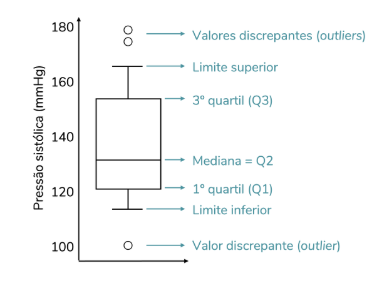

In [ ]:
#boxplot usando seaborn
plt.figure(figsize=(8, 5))
sns.boxplot(y='NOTA_PERCENTUAL', data=df_filtered)
plt.title('Distribuição da nota (%)')
plt.ylabel('Nota (% do total da prova)')
plt.show()

In [ ]:
#boxplot usando plotly
fig = px.box(df_filtered,
             y='NOTA_PERCENTUAL',
             title='Distribuição da nota (%)')
fig.show()

In [ ]:
#boxplot da nota, por turma, usando seaborn
plt.figure(figsize=(8, 5))
sns.boxplot(x='TURMA', y='NOTA_PERCENTUAL', data=df_filtered)
plt.title('Distribuição da nota por turma')
plt.xlabel('Turma')
plt.ylabel('Nota (% do total da prova)')
plt.show()

In [ ]:
#boxplot da nota, por turma, usando plotly
fig = px.box(df_filtered,
             x='TURMA',
             y='NOTA_PERCENTUAL',
             title='Distribuição da nota por turma',
             labels={'TURMA': 'Turma', 'NOTA_PERCENTUAL': 'Nota (%)'})
fig.show()

In [ ]:
#histograma da duração da prova
plt.figure(figsize=(8, 5))
sns.histplot(data=df_filtered, x='DURACAO_CALC_MIN', bins=15)
plt.title('Distribuição do tempo de prova')
plt.xlabel('Duração (minutos)')
plt.ylabel('Quantidade de alunos')
plt.show()

In [ ]:
#relação entre tempo de prova e nota
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_filtered, x='DURACAO_CALC_MIN', y='NOTA_PERCENTUAL', hue='TURMA')
plt.title('Tempo de prova x nota')
plt.xlabel('Duração (minutos)')
plt.ylabel('Nota (%)')
plt.show()

## 8.2) Dados Categóricos

In [ ]:
#Gráfico de contagem, por turma, no seaborn
plt.figure(figsize=(8, 5))
sns.countplot(data=df_filtered, x='TURMA')
plt.title('Quantidade de alunos por turma')
plt.xlabel('Turma')
plt.ylabel('Contagem')
plt.show()

In [ ]:
#Gráfico de contagem, por gênero, no plotly

# cria data frame de contagem
genero_counts = df_filtered['GENERO'].value_counts().reset_index()
genero_counts.columns = ['GENERO', 'count']

#criação do gráfico
fig = px.bar(genero_counts, x='GENERO', y='count',
             title='Quantidade de alunos por gênero',
             labels={'GENERO': 'Gênero', 'count': 'Contagem'})
fig.show()

In [ ]:
#Faixa de desempenho por turma
plt.figure(figsize=(9, 5))
sns.countplot(data=df_filtered, x='TURMA', hue='FAIXA_DESEMPENHO')
plt.title('Faixa de desempenho por turma')
plt.xlabel('Turma')
plt.ylabel('Contagem')
plt.legend(title='Faixa de desempenho')
plt.show()

→ **Antes e depois:** vale a pena lembrar como esse último gráfico ficaria se não tivéssemos tratado a coluna `TURMA`. Rode a célula abaixo usando a base original.

In [ ]:
#O mesmo gráfico, feito com a coluna suja da base original
plt.figure(figsize=(11, 5))
sns.countplot(data=df, x='turma')
plt.title('Quantidade de alunos por turma - SEM tratamento')
plt.xlabel('Turma (como veio do sistema)')
plt.ylabel('Contagem')
plt.xticks(rotation=45, ha='right')
plt.show()

→ Seis vezes mais barras do que turmas. É esse gráfico que vai parar numa apresentação quando ninguém trata os dados antes.

---

# 9) Tratando Outliers

→ Outliers são valores que fogem muito do padrão da maioria dos dados.

→ Eles podem ser causados por erros de digitação, problemas de medição ou até representar casos reais extremos.

→ Identificar e tratar outliers é importante porque eles podem distorcer análises estatísticas e visuais, como média, desvio padrão e gráficos.

→ Algumas estratégias comuns são:

- Análise visual (gráficos como boxplot e histogramas)
- Regras estatísticas (como usar o intervalo interquartil (IQR))
- **Comparação com uma fonte independente** (quando existe)

→ Como tratar outliers?
- Remover os outliers (quando são claramente erros);
- Corrigir valores com base em outras variáveis (se souber o valor real esperado);
- Manter, se forem reais e importantes para a análise.

OBS: um valor fora do padrão nem sempre é um erro. Avalie o contexto antes de decidir o que fazer com ele.

## 9.1) Outliers na duração da prova

In [ ]:
#Visualização dos dois cálculos de duração, lado a lado
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_filtered[['DURACAO_MIN', 'DURACAO_CALC_MIN']])
plt.title('Duração informada pelo sistema x duração calculada pelas datas')
plt.ylabel('Minutos')
plt.show()

→ Aqui temos uma situação privilegiada: **duas medidas da mesma coisa**. Quando elas discordam, sabemos que há erro em uma delas.

→ Vamos usar a regra do IQR (intervalo interquartil) sobre a coluna `DIFERENCA_MIN` para identificar os casos discrepantes.

→ A regra: são considerados outliers os valores abaixo de `Q1 - 1,5 x IQR` ou acima de `Q3 + 1,5 x IQR`.

In [ ]:
#Cálculo dos limites pela regra do IQR
Q1 = df_filtered['DIFERENCA_MIN'].quantile(0.25)
Q3 = df_filtered['DIFERENCA_MIN'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("Q1: ", round(Q1, 2))
print("Q3: ", round(Q3, 2))
print("IQR: ", round(IQR, 2))
print("Limite inferior: ", round(limite_inferior, 2))
print("Limite superior: ", round(limite_superior, 2))

In [ ]:
#Quais registros estão fora dos limites?
outliers_duracao = df_filtered.loc[(df_filtered['DIFERENCA_MIN'] < limite_inferior) |
                                   (df_filtered['DIFERENCA_MIN'] > limite_superior)]

outliers_duracao[['RA', 'INICIADO', 'COMPLETO', 'DURACAO_TEXTO', 'DURACAO_MIN', 'DURACAO_CALC_MIN', 'DIFERENCA_MIN']]

→ Olhe o primeiro caso: o sistema informa "2 horas 20 minutos", mas o aluno iniciou às 11h31 e entregou às 11h52. **21 minutos.**

→ Mas olhe a lista inteira com atenção: alguns registros aparecem ali com diferença de apenas **1 minuto**. Esses não são erros — são arredondamento (o sistema registra o horário sem os segundos). A regra do IQR os pescou porque, nesta base, a maioria das diferenças é tão próxima de zero que o intervalo ficou apertadíssimo (menos de 1 minuto).

→ **Essa é a diferença entre um critério estatístico e uma decisão de análise.** A regra do IQR *sinaliza* candidatos; quem decide o que é erro é você, olhando o contexto. Aqui, os problemas de verdade são os registros com diferença de 60 a 144 minutos.

→ Aqui a decisão é fácil de justificar: as datas de início e entrega são registradas automaticamente pelo sistema; o campo de duração, não. Vamos **confiar nas datas** e usar `DURACAO_CALC_MIN` como a nossa medida oficial de tempo de prova.

→ Note que a decisão **não foi remover as linhas**. Os alunos existem, as notas deles são válidas — o problema estava em uma coluna só.

In [ ]:
#Adoção da duração calculada como medida oficial
df_filtered['DURACAO_FINAL_MIN'] = df_filtered['DURACAO_CALC_MIN']

#Comparação das estatísticas: antes e depois da decisão
df_filtered[['DURACAO_MIN', 'DURACAO_FINAL_MIN']].describe().T.round(2)

→ Repare no impacto: a média do tempo de prova cai de forma expressiva quando trocamos a fonte do dado. **Um único campo mal preenchido estava distorcendo a estatística de toda a turma.**

## 9.2) Outliers na idade

In [ ]:
#boxplot da idade
plt.figure(figsize=(8, 5))
sns.boxplot(y='IDADE', data=df_filtered)
plt.title('Distribuição da idade')
plt.ylabel('Idade (anos)')
plt.show()

In [ ]:
#Quem são os casos extremos?
df_filtered.loc[(df_filtered['IDADE'] < 17) | (df_filtered['IDADE'] > 35),
                ['RA', 'NASCIMENTO_BRUTO', 'ANO_NASCIMENTO', 'IDADE', 'IDADE_IMPUTADA']].sort_values('IDADE')

→ Antes de remover qualquer coisa, volte à coluna `NASCIMENTO_BRUTO` desses alunos e pergunte: **é erro de digitação ou é um aluno real?**

→ Um aluno de 15 anos numa graduação é implausível (provável erro no ano informado). Já um aluno de 38 anos é perfeitamente possível — cursos noturnos têm alunos de todas as idades.

→ **Regra de ouro:** não remova um valor só porque ele é raro. Remova quando você conseguir explicar por que ele é *impossível*.

→ Como exemplo, vamos remover apenas os casos implausíveis para uma graduação (menores de 17 anos):

In [ ]:
#exemplo de remoção de idades implausíveis
print("Shape antes: ", df_filtered.shape)
df_filtered = df_filtered.loc[df_filtered['IDADE'] >= 17]
print("Shape depois: ", df_filtered.shape)

In [ ]:
# Verificar novo shape da tabela e as estatísticas de idade
df_filtered[['IDADE']].describe().T

# 10) Salvando o DataFrame

→ Depois de tratar e organizar os dados, podemos salvar a nova versão da base.

→ Antes disso, uma última limpeza: as colunas brutas (`NASCIMENTO_BRUTO`, `DURACAO_TEXTO`, `DURACAO_MIN`) já cumpriram seu papel e podem sair — mas **só depois** de termos derivado tudo que precisávamos delas.

→ Você pode preferir mantê-las por rastreabilidade. As duas escolhas são defensáveis; o importante é ser consciente da escolha.

In [ ]:
#Seleção das colunas finais da base tratada
colunas_finais = ['RA', 'TURMA', 'GENERO', 'IDADE', 'IDADE_IMPUTADA',
                  'INICIADO', 'COMPLETO', 'DURACAO_FINAL_MIN',
                  'NOTA_FINAL', 'NOTA_PERCENTUAL', 'APROVADO', 'FAIXA_DESEMPENHO'] + variaveis_questoes

df_tratado = df_filtered[colunas_finais].copy()
df_tratado.head()

In [ ]:
#Comparação final: de onde saímos e onde chegamos
print("Base original:  ", df.shape[0], "linhas x", df.shape[1], "colunas")
print("Base tratada:   ", df_tratado.shape[0], "linhas x", df_tratado.shape[1], "colunas")
print()
print("Turmas na base original: ", df['turma'].nunique())
print("Turmas na base tratada:  ", df_tratado['TURMA'].nunique())
print()
print("Formas de escrever o gênero na base original: ", df['genero'].nunique())
print("Categorias de gênero na base tratada:         ", df_tratado['GENERO'].nunique())

→ Para salvar, usamos o método `.to_csv()`:

- O argumento `index=False` evita que o índice do DataFrame vire uma coluna no arquivo;
- O argumento `encoding='utf-8-sig'` garante que os acentos apareçam corretamente ao abrir no Excel;
- No Colab, o arquivo salvo fica acessível na lateral (em "Arquivos") e pode ser baixado manualmente;
- Também é possível salvar direto no Google Drive, usando o caminho completo da pasta.

In [ ]:
#Salvar DataFrame
path_to_save = "dataset_avaliacao_sptech_tratado.csv"
# Exemplo Drive: path_to_save = "/content/drive/MyDrive/dataset_avaliacao_sptech_tratado.csv"

df_tratado.to_csv(path_to_save, index = False, encoding='utf-8-sig')
print("Arquivo salvo em: ", path_to_save)

---

# Resumo: o que fizemos hoje

| Problema encontrado | Onde | Como tratamos |
| --- | --- | --- |
| Encoding errado (acentos quebrados) | Arquivo todo | `encoding='latin1'` na leitura |
| Coluna sem nome | Ano de nascimento | `.rename()` |
| Maiúsculas/minúsculas inconsistentes | `Situação` | `.str.lower()` + `.str.capitalize()` |
| Linhas duplicadas | Base toda | `.drop_duplicates()` + checagem por chave única |
| Vírgula decimal em texto | 28 questões | `.str.replace()` + `.astype(float)` |
| Informação presa no nome da coluna | Valor máximo das questões | `.split('/')` |
| Data em texto e em português | `Iniciado`, `Completo` | dicionário de meses + `pd.to_datetime()` |
| Formato de tempo irregular | `Duração` | expressões regulares (`re`) |
| Campo digitado livremente | Ano de nascimento | regex + regra documentada de completar o ano |
| 17 grafias para 3 categorias | `turma` | regex com borda de palavra (`\b`) |
| 36 grafias para 3 categorias | `genero` | remoção de acentos + função com ordem de testes |
| Valores ausentes | Questões e idade | zero (contexto) e mediana (com coluna sinalizadora) |
| Outliers | Duração e idade | comparação com fonte independente + regra do IQR |

→ **A lição central da aula:** nenhum desses problemas gera mensagem de erro. O Python roda tudo, calcula médias, desenha gráficos bonitos — e entrega números errados em silêncio.

→ O tratamento de dados não é a etapa chata que antecede a análise. **É a análise.**

---

# Exercício Prático

<h3>Parte 1 — Refaça o caminho com os alunos "Em andamento"</h3>

Monte uma base contendo **apenas as provas em andamento** (as que descartamos na seção 2) e responda:

1) Quantas observações temos?

2) Existem valores ausentes ou duplicados?

3) Qual a nota média (%) desse grupo? Ela é comparável com a dos alunos que finalizaram? Por quê?

4) Faz sentido calcular "aprovação" para esse grupo? Justifique.

<h3>Parte 2 — Investigue a base completa</h3>

5) Considerando **todos** os alunos (finalizados e em andamento), qual turma teve o maior tempo médio de prova? Use a duração calculada pelas datas.

6) Existe alguma questão que a maioria dos alunos errou? Monte um ranking das questões pelo percentual de acerto da turma. *(Dica: compare a nota obtida em cada questão com o valor máximo dela.)*

7) Crie um gráfico que compare o desempenho médio das três turmas e escreva **duas frases** interpretando o resultado.

<h3>Parte 3 — Pensamento crítico</h3>

8) Na seção 5.4, adotamos a regra "2 dígitos entre 85 e 99 → anos 1900". Proponha uma regra **diferente** e justifique. Quantos alunos mudariam de idade com a sua regra?

9) Escolhemos preencher as questões em branco com zero. Refaça o cálculo da `NOTA_FINAL` preenchendo com a **média da questão** e compare os resultados. Quantos alunos mudariam de faixa de desempenho?

10) Aponte **um** problema de qualidade de dados que ficou nesta base e que não tratamos na aula de hoje.